# Signals and system Assignment

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from IPython.display import display, Audio

Sampling frequency (fs): 16000 Hz
Total samples: 165881
Duration: 10.37 seconds


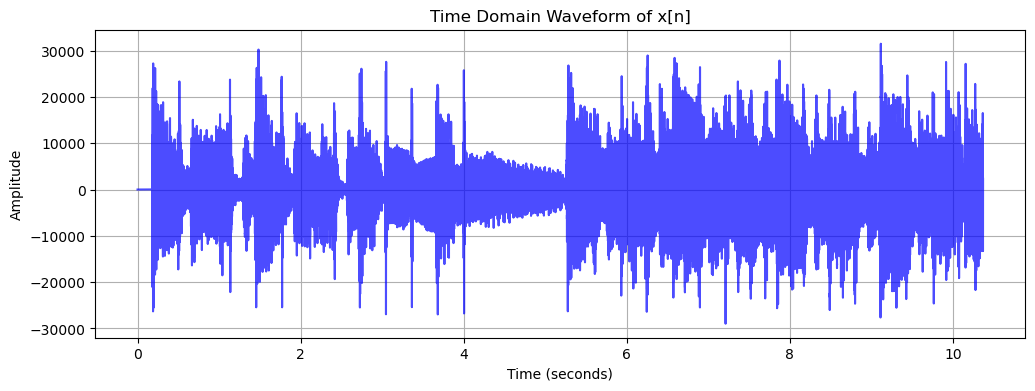

In [2]:
fs, x = wavfile.read('Main_Audio.wav')

print(f"Sampling frequency (fs): {fs} Hz")
print(f"Total samples: {len(x)}")
print(f"Duration: {len(x) / fs:.2f} seconds")

# We plotted the waveform of x[n]
plt.figure(figsize=(12, 4))
time = np.linspace(0, len(x) / fs, num=len(x))
plt.plot(time, x, color='blue', alpha=0.7)
plt.title('Time Domain Waveform of x[n]')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.grid(True)
plt.show()

# Generated an interactive player
display(Audio(x, rate=fs))

In [3]:
# Took few arbitrary values of N to Check its effect in the output .
N_values = [5, 100, 10000]

print("Original Audio:")
display(Audio(x, rate=fs))
print("Filtered Audio:")
for N in N_values:
    #Generating h[n]
    h_len = 2 * N + 1
    h = np.ones(h_len) / h_len
    
    # Convolving x[n] with h[n]
    y = np.convolve(x, h, mode='same')
    
    print(f"N = {N}")
    display(Audio(y, rate=fs))

Original Audio:


Filtered Audio:
N = 5


N = 100


N = 10000


In [4]:
#We are choosing integer values randomly between [-10,10] for creating noise
eta=np.random.randint(-10 ,10, len(x))

# Defined different values of the strength
strength = [10, 50, 250] 

# Took few arbitrary values of N to Check its effect in the output
N_values = [5, 100, 10000] 



for s in strength:
    # Observation after adding noise with strength s
    x1 = x + s * eta
    
    if(s==10):
        print("Unfiltered Noisy Audio (x1[n]):")
        display(Audio(x1, rate=fs))
    print(f"Testing noise with strength: {s}")
    
    for N in N_values:
        h_len = 2 * N + 1
        h = np.ones(h_len) / h_len
        
        # Convolve x1[n] with h[n]
        y_noisy = np.convolve(x1, h, mode='same')
        
        print(f"N = {N}:")
        display(Audio(y_noisy, rate=fs))

Unfiltered Noisy Audio (x1[n]):


Testing noise with strength: 10
N = 5:


N = 100:


N = 10000:


Testing noise with strength: 50
N = 5:


N = 100:


N = 10000:


Testing noise with strength: 250
N = 5:


N = 100:


N = 10000:


In [5]:
N_values = [5, 100, 10000] 

print("Original Noisy Audio (x1[n]):")
display(Audio(x1, rate=fs))

print("Frequency domain filtered audio: ")
for N in N_values:
    h_len = 2 * N + 1
    h = np.ones(h_len) / h_len
    
    L = len(x1) + len(h) - 1
    
    Xw = np.fft.fft(x1, n=L)
    Hw = np.fft.fft(h, n=L)
    Yw = Xw * Hw
    
    # Compute the inverse FFT
    y_freq_full = np.fft.ifft(Yw).real
    
    y_freq = y_freq_full[N : N + len(x1)]
    
    print(f"N = {N}")
    display(Audio(y_freq, rate=fs))

Original Noisy Audio (x1[n]):


Frequency domain filtered audio: 
N = 5


N = 100


N = 10000


In [6]:
N = 50 
h_len = 2 * N + 1
h = np.ones(h_len) / h_len

eta=np.random.randint(-10 ,10, len(x))
sigma = 5

# Create the observation y[n] = x[n]*h[n] + noise
y = np.convolve(x, h, mode='same') + sigma * eta

print("Noisy Audio:")
display(Audio(y, rate=fs))

Y_w = np.fft.fft(y)
H_w = np.fft.fft(h, n=len(y))
X_hat_w = Y_w / (H_w + 0.1)
x_hat = np.fft.ifft(X_hat_w).real
    
print(f"Recovered Audio:")
display(Audio(x_hat, rate=fs))

Noisy Audio:


Recovered Audio:
